In [ ]:
#LINEAR REGRESSION AND COMPUTING ACCURACY
#23BDS0030

DATASET SHAPE: (1592, 11)

FIRST FIVE ROWS


,rownames,Gunnel,Time,Fromlow,Slope,Rw,Amphiso,Subst,Pool,Water,Cobble
0,1,0,786,190,10,0.1,0,3,0,0,0
1,2,0,794,182,10,0.0,0,3,0,0,0
2,3,0,798,178,20,0.0,0,1,0,0,0
3,4,0,800,176,70,0.3,0,1,0,1,0
4,5,0,804,172,40,0.3,0,1,0,1,0



COLUMN NAMES
['rownames', 'Gunnel', 'Time', 'Fromlow', 'Slope', 'Rw', 'Amphiso', 'Subst', 'Pool', 'Water', 'Cobble']

DATA TYPES
rownames      int64
Gunnel        int64
Time          int64
Fromlow       int64
Slope         int64
Rw          float64
Amphiso       int64
Subst         int64
Pool          int64
Water         int64
Cobble        int64
dtype: object

MISSING VALUES
rownames    0
Gunnel      0
Time        0
Fromlow     0
Slope       0
Rw          0
Amphiso     0
Subst       0
Pool        0
Water       0
Cobble      0
dtype: int64

STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
rownames,1592.0,796.500000,459.715129,1.0,398.75,796.5,1194.25,1592.0
Gunnel,1592.0,0.030151,0.171056,0.0,0.00,0.0,0.00,1.0
Time,1592.0,705.243719,135.853638,340.0,623.00,712.5,810.00,983.0
Fromlow,1592.0,149.408920,82.662326,0.0,71.75,158.0,224.25,304.0
Slope,1592.0,9.503769,15.889862,0.0,0.00,0.0,10.00,90.0
Rw,1592.0,0.527073,0.421278,0.0,0.00,0.6,1.00,1.0
Amphiso,1592.0,0.464196,0.899039,0.0,0.00,0.0,1.00,4.0
Subst,1592.0,3.105528,2.787720,1.0,1.00,2.0,4.00,13.0
Pool,1592.0,0.202261,0.401812,0.0,0.00,0.0,0.00,1.0
Water,1592.0,0.508794,0.500080,0.0,0.00,1.0,1.00,1.0


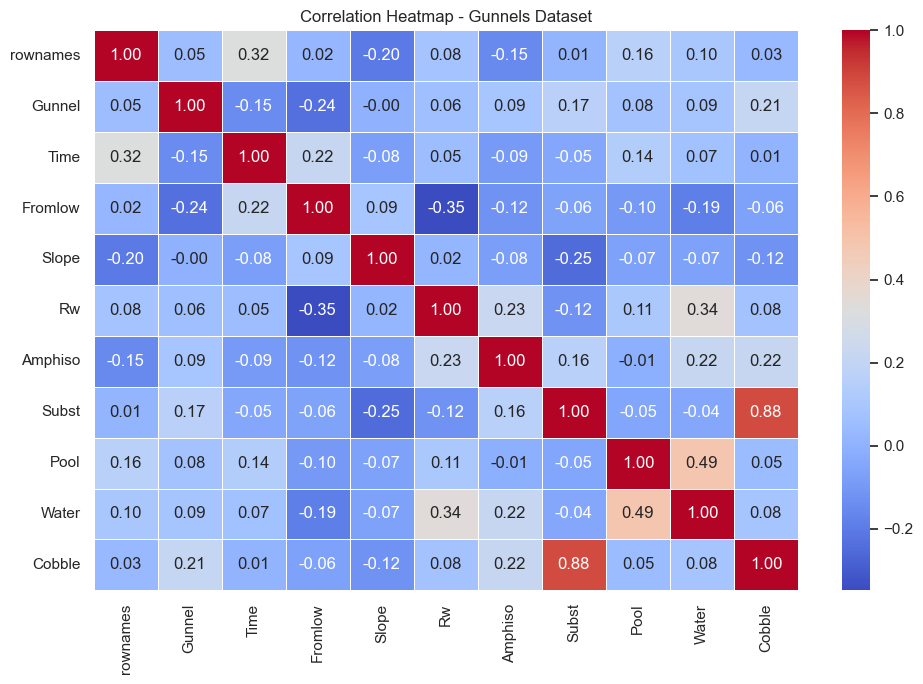

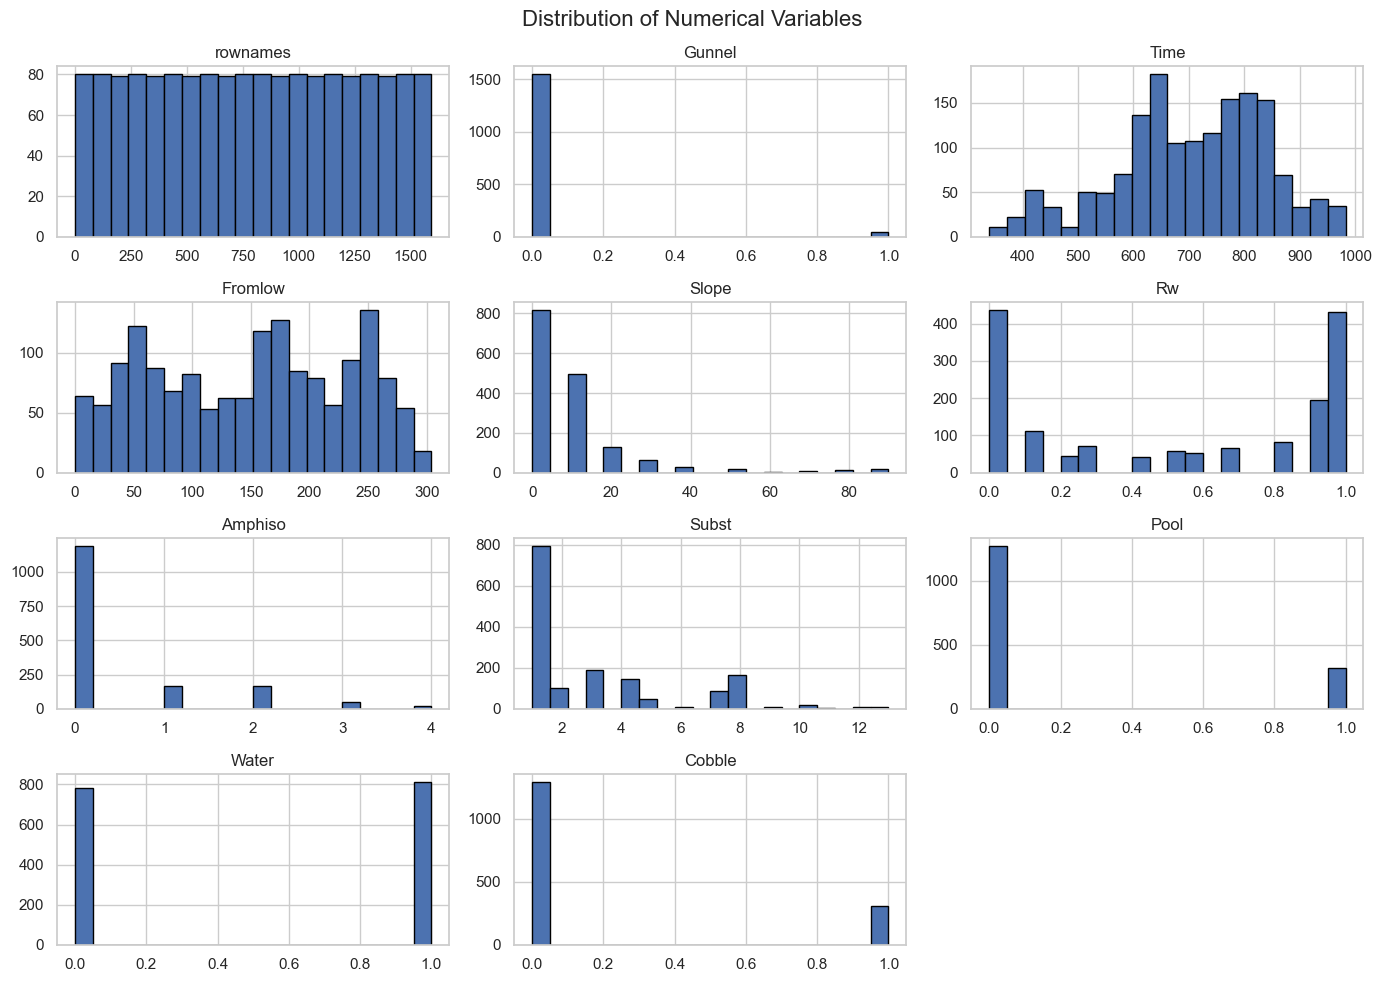


TARGET VARIABLE: Cobble

Available numerical columns: ['rownames', 'Gunnel', 'Time', 'Fromlow', 'Slope', 'Rw', 'Amphiso', 'Subst', 'Pool', 'Water', 'Cobble']

LINEAR REGRESSION MODEL EVALUATION
R-squared (R²): 0.8149
Mean Absolute Error (MAE): 0.1199
Mean Squared Error (MSE): 0.0249
Root Mean Squared Error (RMSE): 0.1577


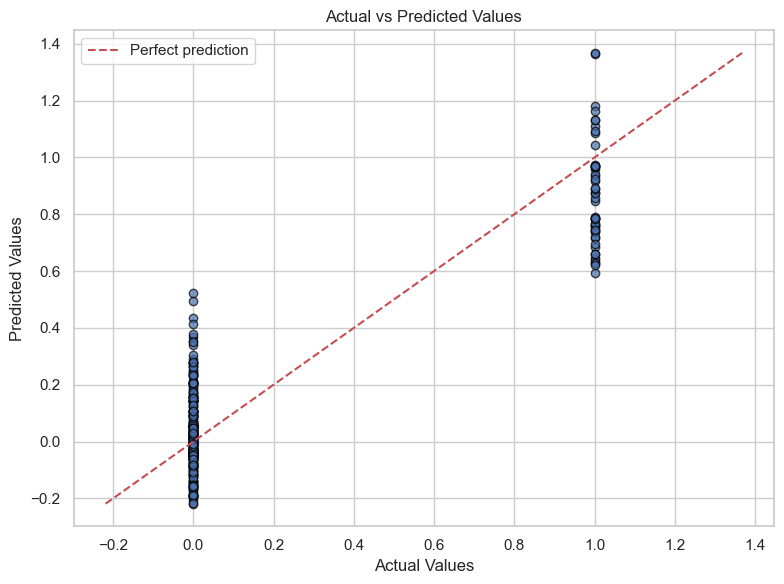

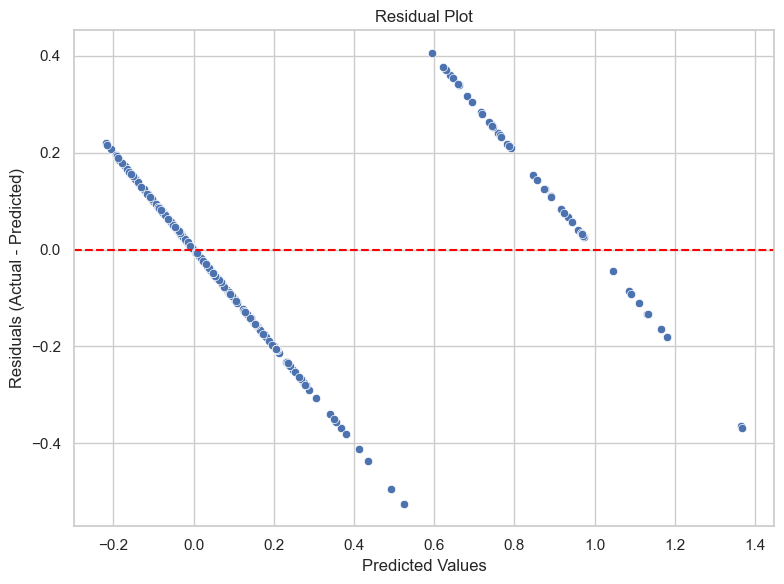

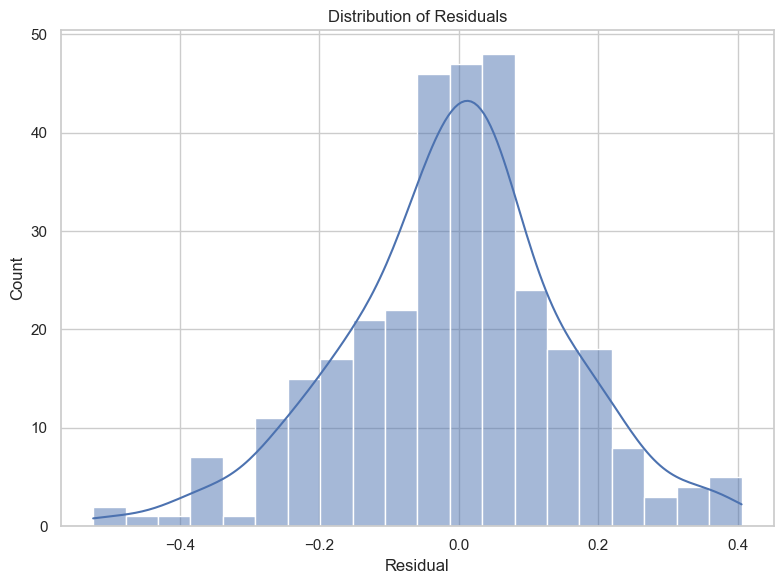

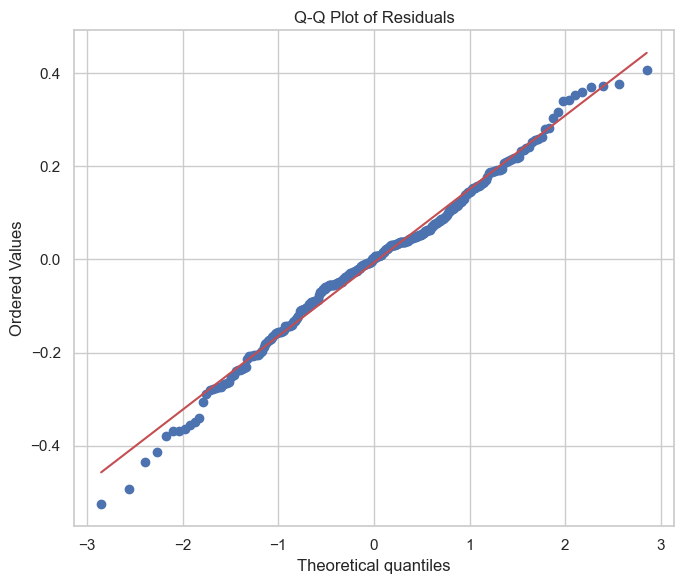

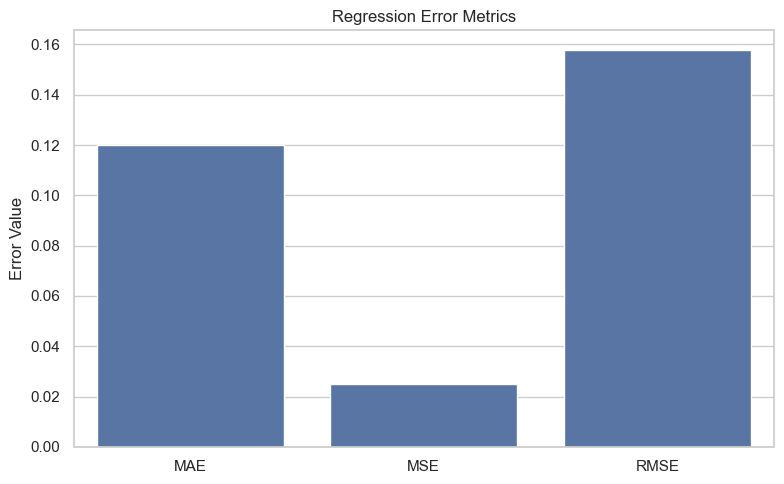


ACTUAL VS PREDICTED VALUES


,Actual,Predicted,Residual
0,0,-0.052547,0.052547
1,0,0.289091,-0.289091
2,0,-0.079550,0.079550
3,0,0.038054,-0.038054
4,0,0.019300,-0.019300
5,0,0.213628,-0.213628
6,0,0.054134,-0.054134
7,0,-0.006769,0.006769
8,0,0.108120,-0.108120
9,1,0.640387,0.359613


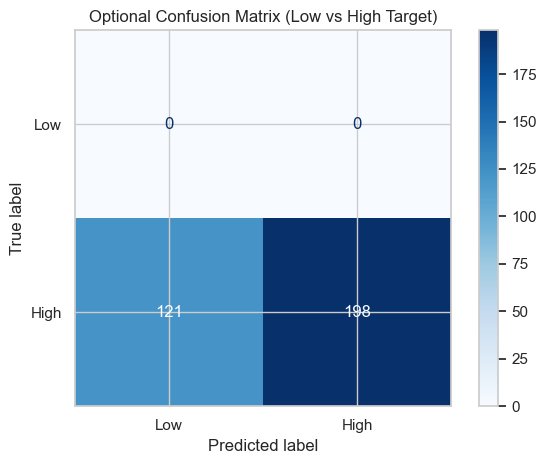


Optional Low/High Classification Accuracy: 62.07%


In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

#Load dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Gunnels.csv"
df = pd.read_csv(url)

print("DATASET SHAPE:", df.shape)
print("\nFIRST FIVE ROWS")
display(df.head())

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nSTATISTICAL SUMMARY")
display(df.describe(include="all").T)

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Select numeric columns and check correlations
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )
    plt.title("Correlation Heatmap - Gunnels Dataset")
    plt.tight_layout()
    plt.show()

#  Plot numerical feature distributions
if numeric_df.shape[1] > 0:
    numeric_df.hist(figsize=(14, 10), bins=20, edgecolor="black")
    plt.suptitle("Distribution of Numerical Variables", fontsize=16)
    plt.tight_layout()
    plt.show()

# Choose the target variable

target = numeric_df.columns[-1] if len(numeric_df.columns) > 0 else None

if target is None:
    raise ValueError("The dataset has no numerical columns for linear regression.")

print("\nTARGET VARIABLE:", target)
print("\nAvailable numerical columns:", numeric_df.columns.tolist())

# Prepare features and target
data = df.copy()
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=[target])

X = data.drop(columns=[target])
y = data[target]

# Remove columns with no usable values
X = X.dropna(axis=1, how="all")

# Remove identifier-like columns with unique values in every row
id_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=True) == len(X)
]
X = X.drop(columns=id_columns)

if X.shape[1] == 0:
    raise ValueError("No usable predictor columns remain after preprocessing.")

# Identify numeric and categorical predictors
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

transformers = []

if numeric_features:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])
    transformers.append(("numeric", numeric_pipeline, numeric_features))

if categorical_features:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

#  Construct the linear regression model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

#  Make predictions
y_pred = model.predict(X_test)

#  Evaluate the model
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("\nLINEAR REGRESSION MODEL EVALUATION")

print(f"R-squared (R²): {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# Actual versus predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, edgecolor="black")

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], "r--", label="Perfect prediction")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")
plt.legend()
plt.tight_layout()
plt.show()

#  Residual plot
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

#  Residual distribution
plt.figure(figsize=(8, 6))
sns.histplot(residuals, kde=True, bins=20)
plt.xlabel("Residual")
plt.title("Distribution of Residuals")
plt.tight_layout()
plt.show()

#  Residual Q-Q plot
import scipy.stats as stats

plt.figure(figsize=(7, 6))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.tight_layout()
plt.show()

#  Regression error comparison
error_values = {
    "MAE": mae,
    "MSE": mse,
    "RMSE": rmse
}

plt.figure(figsize=(8, 5))
sns.barplot(
    x=list(error_values.keys()),
    y=list(error_values.values())
)
plt.title("Regression Error Metrics")
plt.ylabel("Error Value")
plt.tight_layout()
plt.show()

#  Display actual and predicted values
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Residual": residuals
})

print("\nACTUAL VS PREDICTED VALUES")
display(results.head(15))

#  Confusion matrix 

threshold = y_train.median()

y_test_class = (y_test.to_numpy() >= threshold).astype(int)
y_pred_class = (y_pred >= threshold).astype(int)

cm = confusion_matrix(y_test_class, y_pred_class, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "High"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Optional Confusion Matrix (Low vs High Target)")
plt.tight_layout()
plt.show()

# Threshold-based classification accuracy
classification_accuracy = np.mean(y_test_class == y_pred_class)

print(f"\nOptional Low/High Classification Accuracy: "
      f"{classification_accuracy * 100:.2f}%")
